# Funding, Domain & Timeline Analysis of GDPR Projects

29 EU-funded GDPR projects from `gdpr_projects.csv`, classified into 8 sectors.

Produces figures for §VI of the paper:
- **Fig: Total Funding by Sector** (`fund_new.png`)
- **Fig: Average Funding by Sector** (`fund_avg.png`)
- **Fig: Funding Distribution** (`fund_2_2.png`)
- **Fig: Projects per Domain** (`project_per_domain.png`)
- **Fig: Projects per Year** (`active_projects.png`)
- **Fig: Domain × Year Heatmap** (`domain_year_count_heatmap.png`)
- **Fig: Funding vs Duration** (`funding_vs_duration.png`)
- **Fig: Correlation Plots** (`correlation_plots.png`)
- **Fig: Project Timeline (Gantt)** (`project_timeline.png`)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 150

IMGDIR = '../_IEEE_Communications_Surveys___Tutorials__survey/images/'

In [2]:
df = pd.read_csv('gdpr_projects.csv')
df['start_date'] = pd.to_datetime(df['start_date'])
df['end_date'] = pd.to_datetime(df['end_date'])
df['duration_months'] = ((df['end_date'] - df['start_date']).dt.days / 30.44).round(0).astype(int)
df['start_year'] = df['start_date'].dt.year

# Use the sector column directly
print(f'Projects: {len(df)}')
print(f'\nSector distribution:')
print(df['sector'].value_counts().to_string())
print(f'\nFunded projects: {df["funding_eur"].notna().sum()}')

# Consistent color palette for 8 sectors
SECTOR_ORDER = [
    'Privacy Technology', 'SME Compliance', 'Healthcare',
    'Data Economy', 'Multi-Sector', 'Public Administration',
    'Online Advertising', 'Education'
]
SECTOR_COLORS = {
    'Privacy Technology':    '#4472C4',
    'SME Compliance':        '#C0504D',
    'Healthcare':            '#9BBB59',
    'Data Economy':          '#8064A2',
    'Multi-Sector':          '#4BACC6',
    'Public Administration': '#F79646',
    'Online Advertising':    '#244185',
    'Education':             '#943634',
}

df_funded = df.dropna(subset=['funding_eur'])

Projects: 29

Sector distribution:
sector
Privacy Technology       6
SME Compliance           6
Multi-Sector             4
Healthcare               4
Data Economy             4
Public Administration    3
Online Advertising       1
Education                1

Funded projects: 28


## 1. Total Funding by Sector (horizontal bar)

Replaces `fund_new.png`. Shows total EU funding summed across all projects in each sector.

In [ ]:
# Total funding by sector — descending order
sector_funding = df_funded.groupby('sector')['funding_eur'].sum().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(14, 8))
colors = [SECTOR_COLORS[s] for s in sector_funding.index]
bars = ax.barh(sector_funding.index, sector_funding.values / 1e6, color=colors, edgecolor='white', linewidth=0.5)

for bar, val in zip(bars, sector_funding.values):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f'€{val/1e6:.1f}M', va='center', fontsize=22, fontweight='bold')

ax.set_xlabel('Total Funding (€M)', fontsize=26)
ax.set_ylabel('Sector', fontsize=26)
ax.tick_params(axis='both', labelsize=22)
ax.set_xlim(0, sector_funding.max() / 1e6 * 1.25)
ax.xaxis.grid(True, alpha=0.3, linestyle='--')
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f'{IMGDIR}fund_new.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('fund_new.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: fund_new.png')

## 2. Average Funding by Sector

Replaces `fund_avg.png`. Shows mean funding per project in each sector.

In [ ]:
# Average funding by sector — descending order
sector_avg = df_funded.groupby('sector')['funding_eur'].mean().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(14, 8))
colors = [SECTOR_COLORS[s] for s in sector_avg.index]
bars = ax.barh(sector_avg.index, sector_avg.values / 1e6, color=colors, edgecolor='white', linewidth=0.5)

for bar, val in zip(bars, sector_avg.values):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
            f'€{val/1e6:.1f}M', va='center', fontsize=22, fontweight='bold')

ax.set_xlabel('Average Funding per Project (€M)', fontsize=26)
ax.set_ylabel('Sector', fontsize=26)
ax.tick_params(axis='both', labelsize=22)
ax.set_xlim(0, sector_avg.max() / 1e6 * 1.3)
ax.xaxis.grid(True, alpha=0.3, linestyle='--')
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f'{IMGDIR}fund_avg.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('fund_avg.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: fund_avg.png')

## 3. Funding Distribution (pie chart)

Replaces `fund_2_2.png`. Shows proportion of total funding by sector.

In [ ]:
# Pie chart with funding table — no % on pie, legend below pie
sector_funding_pie = df_funded.groupby('sector')['funding_eur'].sum().sort_values(ascending=False)
total_funding = sector_funding_pie.sum()
colors = [SECTOR_COLORS[s] for s in sector_funding_pie.index]

fig, (ax_pie, ax_tbl) = plt.subplots(1, 2, figsize=(20, 9), gridspec_kw={'width_ratios': [1, 0.7]})

# Pie chart — no autopct labels
wedges, texts = ax_pie.pie(
    sector_funding_pie.values,
    labels=None,
    colors=colors,
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)

# Legend with percentages — placed outside the pie at bottom
pcts = sector_funding_pie.values / total_funding * 100
legend_labels = [f'{s} ({p:.1f}%)' for s, p in zip(sector_funding_pie.index, pcts)]
ax_pie.legend(wedges, legend_labels, fontsize=14, loc='upper center',
              bbox_to_anchor=(0.5, -0.02), ncol=2,
              framealpha=0.95, edgecolor='#cccccc')

# Funding table
ax_tbl.axis('off')
table_data = [[s, f'€{v/1e6:.2f}M'] for s, v in sector_funding_pie.items()]
table_data.append(['Total Funding', f'€{total_funding/1e6:.2f}M'])

tbl = ax_tbl.table(
    cellText=table_data,
    colLabels=['Sector', 'Funding'],
    cellLoc='center',
    loc='center',
    colWidths=[0.55, 0.35]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(17)
tbl.scale(1, 2.0)

# Style header row
for j in range(2):
    tbl[0, j].set_facecolor('#4472C4')
    tbl[0, j].set_text_props(color='white', fontweight='bold')
# Style total row
last_row = len(table_data)
for j in range(2):
    tbl[last_row, j].set_facecolor('#D9E2F3')
    tbl[last_row, j].set_text_props(fontweight='bold')

plt.tight_layout()
plt.savefig(f'{IMGDIR}fund_2_2.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('fund_2_2.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: fund_2_2.png')

## 4. Projects per Sector

Replaces `project_per_domain.png`. Count of projects in each sector.

In [ ]:
# Projects per sector
sector_count = df.groupby('sector')['project_name'].count().reindex(SECTOR_ORDER).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(14, 8))
colors = [SECTOR_COLORS[s] for s in sector_count.index]
bars = ax.barh(sector_count.index, sector_count.values, color=colors, edgecolor='white', linewidth=0.5)

for bar, val in zip(bars, sector_count.values):
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height() / 2,
            str(val), va='center', fontsize=24, fontweight='bold')

ax.set_xlabel('Number of Projects', fontsize=26)
ax.set_ylabel('Sector', fontsize=26)
ax.tick_params(axis='both', labelsize=22)
ax.set_xlim(0, sector_count.max() * 1.25)
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.xaxis.grid(True, alpha=0.3, linestyle='--')
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(f'{IMGDIR}project_per_domain.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('project_per_domain.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: project_per_domain.png')

## 5. Projects per Year

Replaces `active_projects.png`. Count of projects starting each year.

In [ ]:
from scipy.interpolate import make_interp_spline

# Projects per year + funding spline (dual-axis)
all_years = list(range(2015, 2025))
year_count = df.groupby('start_year')['project_name'].count().reindex(all_years, fill_value=0)
year_funding = df_funded.groupby('start_year')['funding_eur'].sum().reindex(all_years, fill_value=0)

fig, ax1 = plt.subplots(figsize=(16, 9))

# --- Left axis: bar chart of project counts ---
bar_colors = ['#C0504D' if y == 2018 else '#4472C4' for y in all_years]
bars = ax1.bar(
    [str(y) for y in all_years], year_count.values,
    color=bar_colors, edgecolor='white', linewidth=0.5, alpha=0.75,
    label='Number of projects'
)

# Count labels — placed INSIDE the bar (center) to avoid collision with funding labels
for bar, val in zip(bars, year_count.values):
    if val > 0:
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2,
                 str(val), ha='center', va='center', fontsize=20, fontweight='bold',
                 color='white' if val >= 3 else '#333333')

ax1.set_xlabel('Start Year', fontsize=26)
ax1.set_ylabel('Number of Projects', fontsize=24, color='#4472C4')
ax1.tick_params(axis='both', labelsize=20)
ax1.tick_params(axis='y', labelcolor='#4472C4')
ax1.set_ylim(0, year_count.max() * 1.5)
ax1.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax1.yaxis.grid(True, alpha=0.2, linestyle='--')
ax1.set_axisbelow(True)
ax1.spines['top'].set_visible(False)

# GDPR enforcement annotation — move further right to avoid 2018 bar area
ax1.annotate(
    'GDPR\nEnforcement',
    xy=(3, year_count.values[3]),
    xytext=(5.5, year_count.max() * 1.2),
    fontsize=16, color='#C0504D', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#C0504D', lw=2)
)

# --- Right axis: funding spline ---
ax2 = ax1.twinx()

x_pts = np.arange(len(all_years), dtype=float)
y_pts = year_funding.values / 1e6

# Only fit spline through years with nonzero funding
mask = y_pts > 0
if mask.sum() >= 4:
    x_smooth = np.linspace(x_pts[mask][0], x_pts[mask][-1], 200)
    spline = make_interp_spline(x_pts[mask], y_pts[mask], k=3)
    y_smooth = np.clip(spline(x_smooth), 0, None)
    ax2.plot(x_smooth, y_smooth, color='#9BBB59', linewidth=3.0, label='Total funding (€M)')
    ax2.scatter(x_pts[mask], y_pts[mask], color='#9BBB59', s=80, zorder=5, edgecolors='white', linewidth=0.5)

    # Funding labels — always placed ABOVE the spline with enough clearance
    # Custom offsets to avoid overlap with bars and count labels
    y_max = max(y_pts)
    funding_offsets = {}  # year_index: (x_offset, y_offset, ha, va)
    for i in np.where(mask)[0]:
        val = y_pts[i]
        if val >= 1:
            label = f'€{val:.1f}M'
        elif val > 0:
            label = f'€{val:.2f}M'
        else:
            continue

        # Default: place above the dot
        x_off, y_off, ha, va = 0, y_max * 0.08, 'center', 'bottom'

        # Specific adjustments for problematic years
        yr = all_years[i]
        if yr == 2018:  # tallest bar — shift label to the right
            x_off, ha = 0.4, 'left'
            y_off = y_max * 0.06
        elif yr == 2019:  # overlaps with count=3
            x_off, ha = -0.35, 'right'
        elif yr == 2020:  # overlaps with count=6
            y_off = y_max * 0.10
        elif yr == 2022:
            x_off, ha = 0.35, 'left'

        ax2.text(x_pts[i] + x_off, val + y_off, label,
                 ha=ha, va=va, fontsize=14, color='#5A7D2C', fontweight='bold')

ax2.set_ylabel('Total Funding (€M)', fontsize=24, color='#9BBB59')
ax2.tick_params(axis='y', labelsize=20, labelcolor='#9BBB59')
ax2.set_ylim(0, max(y_pts) * 1.5)
ax2.spines['top'].set_visible(False)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=16,
           framealpha=0.95, edgecolor='#cccccc')

plt.tight_layout()
plt.savefig(f'{IMGDIR}active_projects.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('active_projects.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: active_projects.png')

## 6. Sector × Year Heatmap (project count)

Shows how many projects started in each sector per year. Replaces the old 11-domain heatmap.

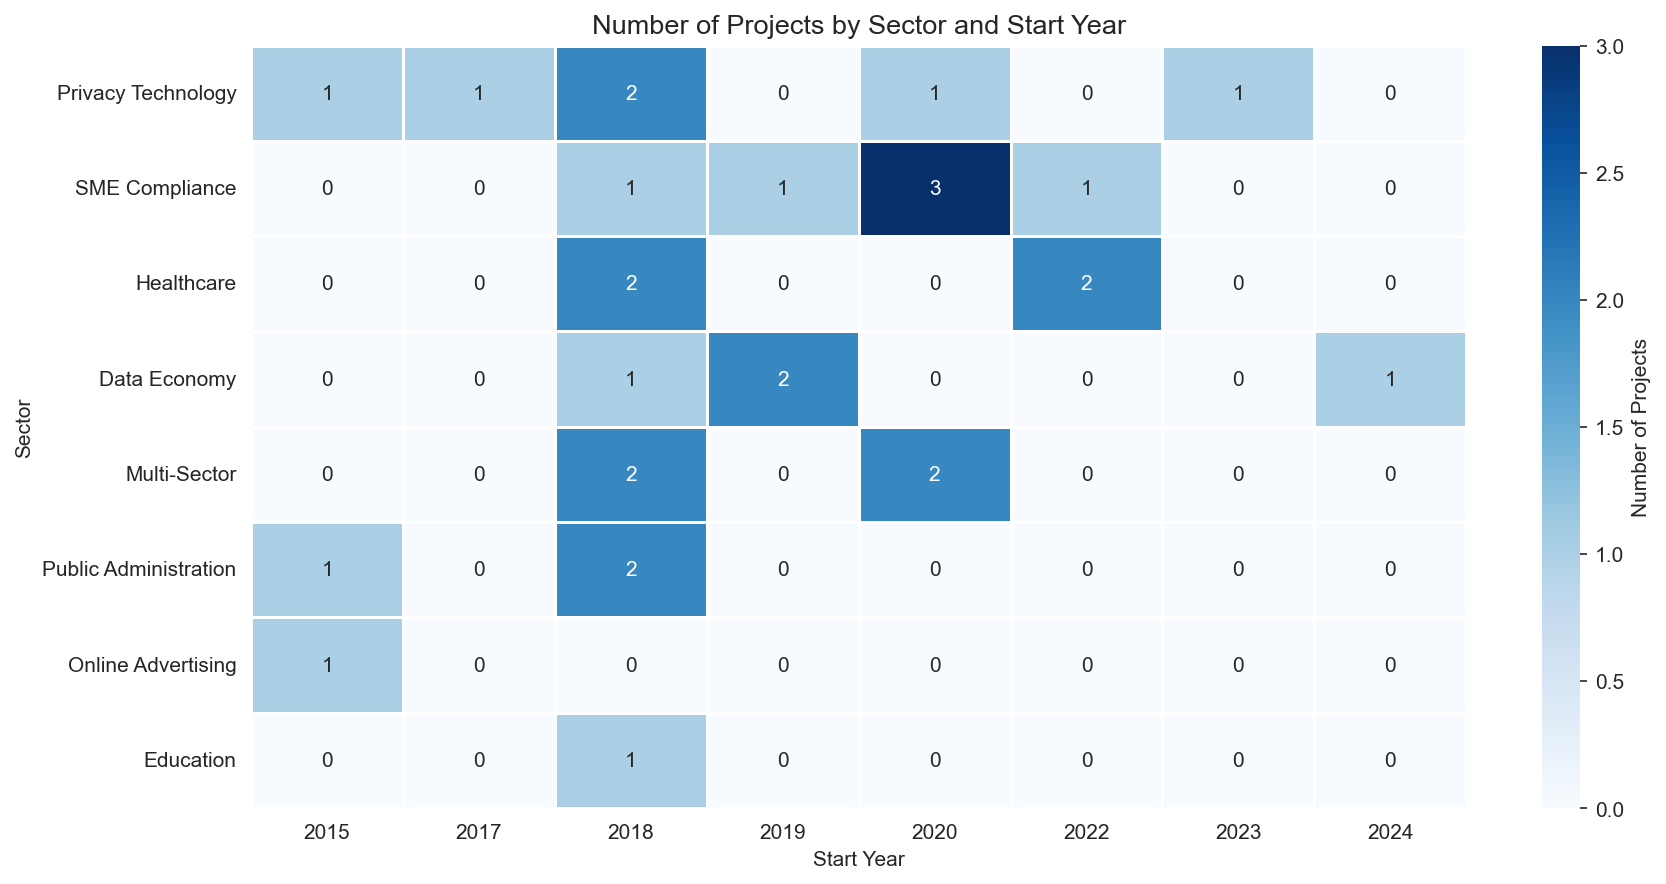

Saved: domain_year_count_heatmap.png


In [8]:
# Sector × Year count heatmap
pivot_count = df.pivot_table(
    index='sector',
    columns='start_year',
    values='project_name',
    aggfunc='count',
    fill_value=0
).reindex(SECTOR_ORDER)

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(
    pivot_count,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Number of Projects'}
)
ax.set_title('Number of Projects by Sector and Start Year', fontsize=13)
ax.set_xlabel('Start Year')
ax.set_ylabel('Sector')
plt.tight_layout()
plt.savefig(f'{IMGDIR}domain_year_count_heatmap.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('domain_year_count_heatmap.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: domain_year_count_heatmap.png')

## 6b. Sector × Year Heatmap (total funding €M)

Same breakdown but summing funding instead of counting projects. Separates "one expensive project" from "many small ones."

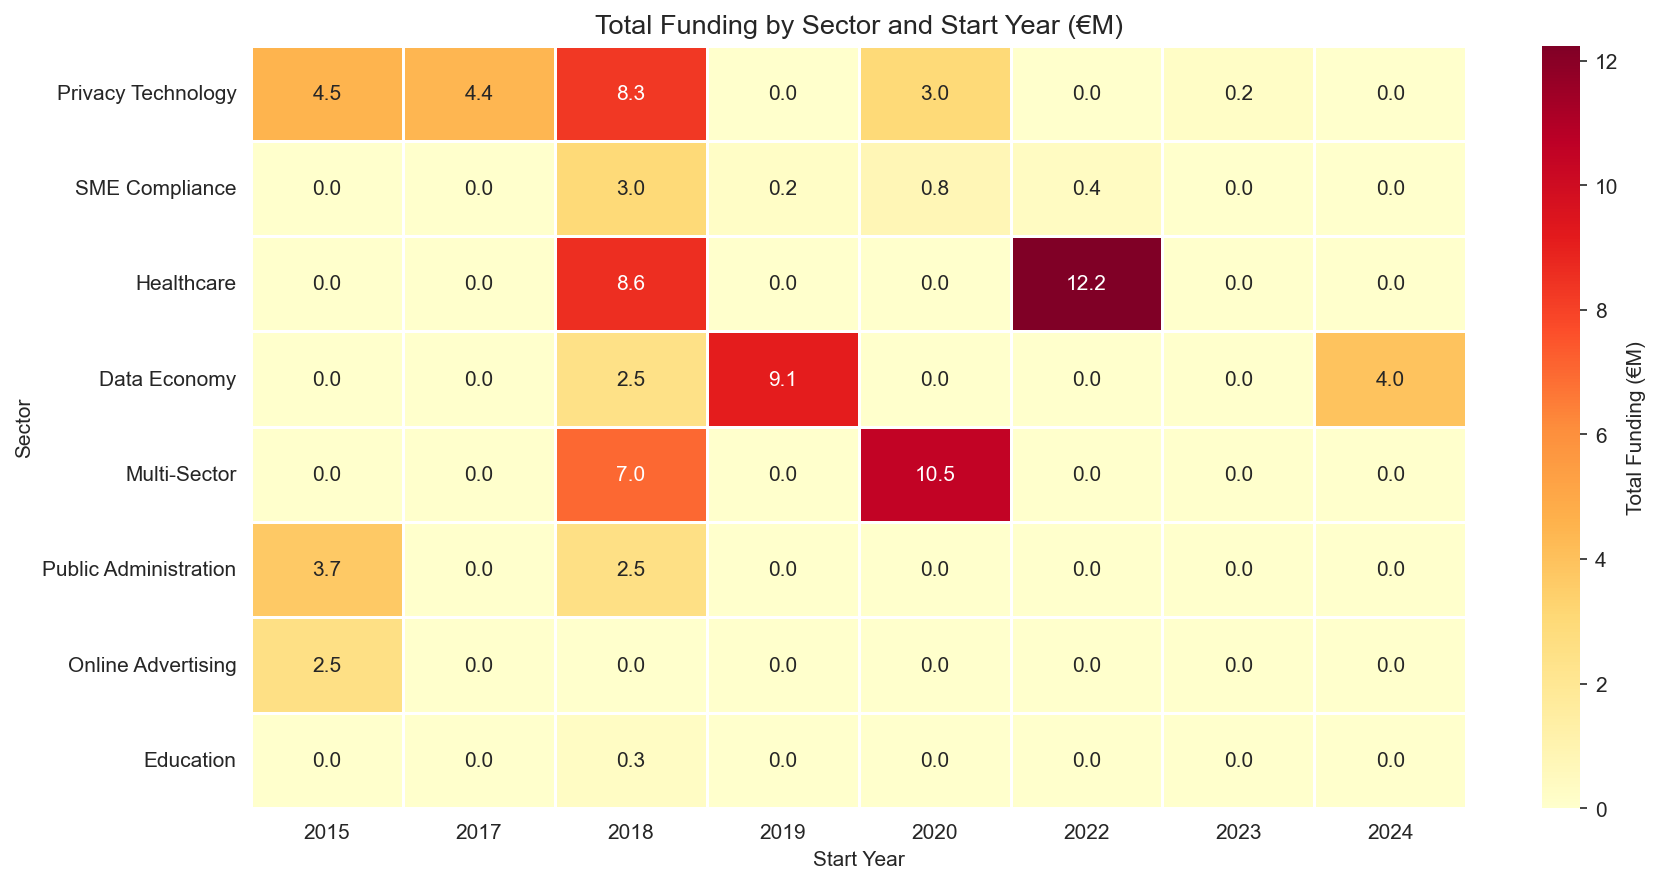

Saved: domain_year_funding_heatmap.png


In [9]:
# Sector × Year funding heatmap (€M)
pivot_funding = df.pivot_table(
    index='sector',
    columns='start_year',
    values='funding_eur',
    aggfunc='sum',
    fill_value=0
).reindex(SECTOR_ORDER)

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(
    pivot_funding / 1e6,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Total Funding (€M)'}
)
ax.set_title('Total Funding by Sector and Start Year (€M)', fontsize=13)
ax.set_xlabel('Start Year')
ax.set_ylabel('Sector')
plt.tight_layout()
plt.savefig(f'{IMGDIR}domain_year_funding_heatmap.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('domain_year_funding_heatmap.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: domain_year_funding_heatmap.png')

## 7. Funding vs Duration (scatter, colored by sector)

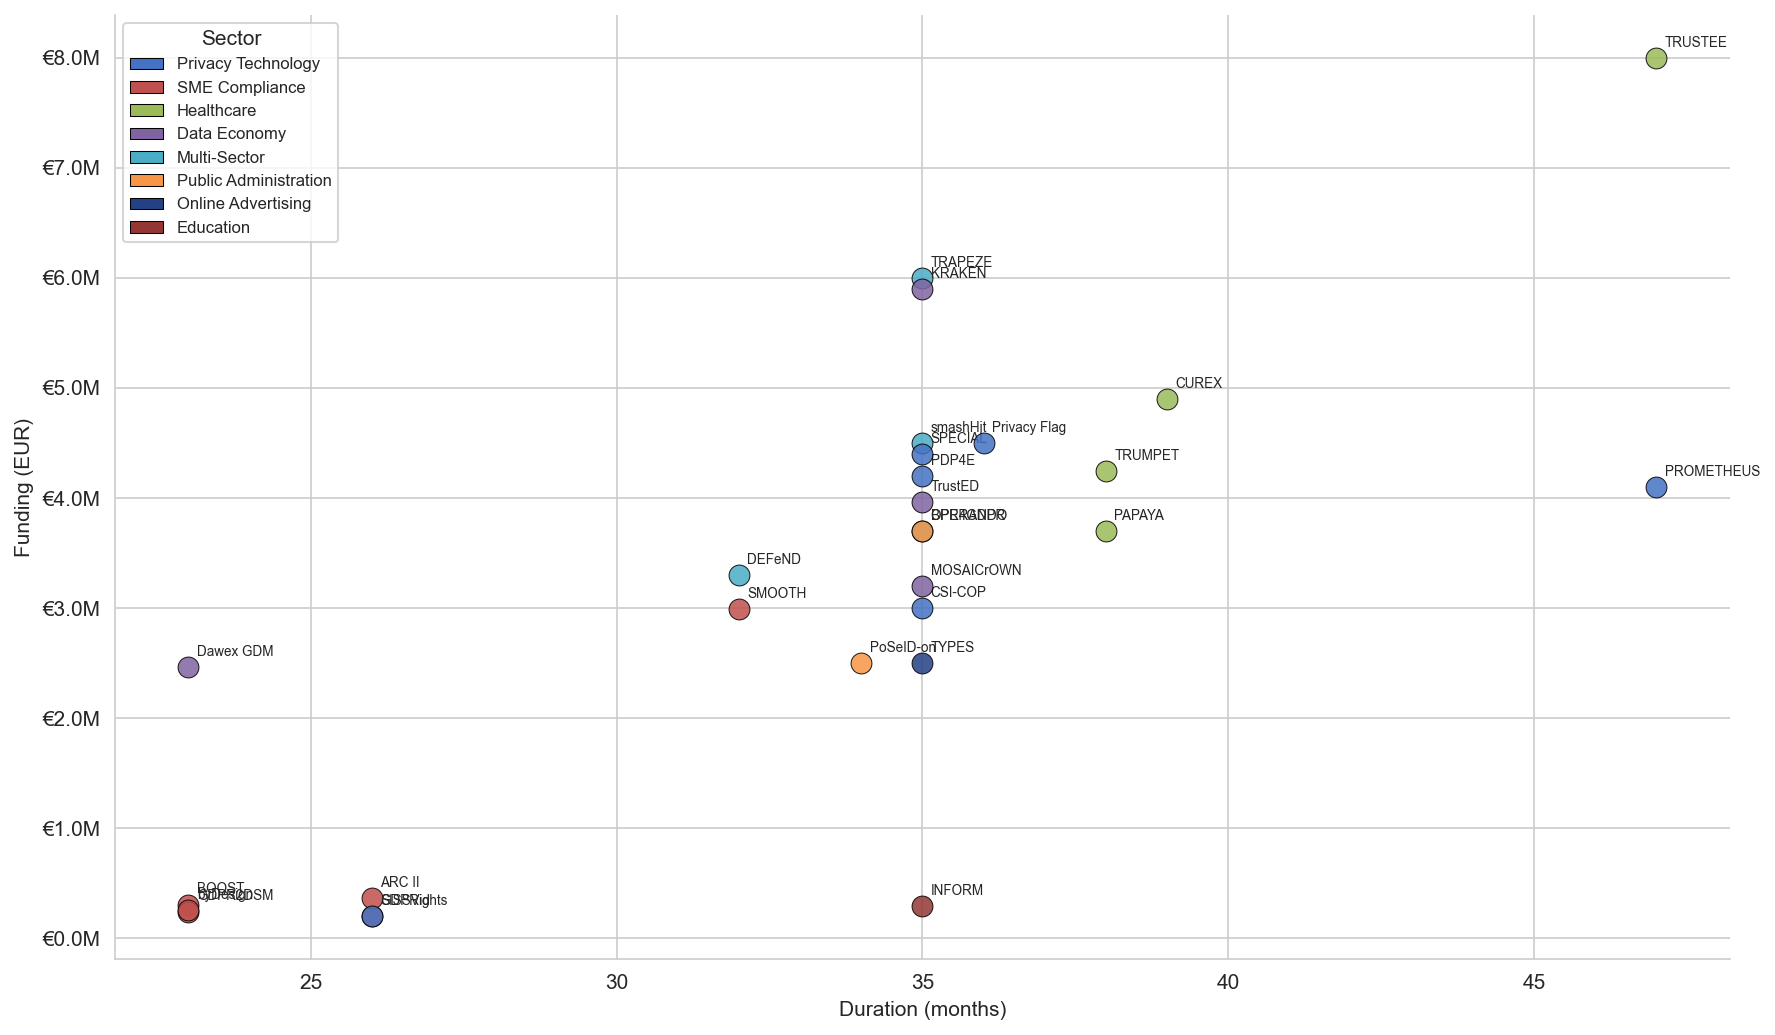

Saved: funding_vs_duration.png


In [10]:
fig, ax = plt.subplots(figsize=(12, 7))

for _, row in df_funded.iterrows():
    ax.scatter(
        row['duration_months'], row['funding_eur'],
        c=[SECTOR_COLORS.get(row['sector'], 'gray')],
        s=100, edgecolors='black', linewidth=0.5, alpha=0.85, zorder=3
    )
    ax.annotate(row['project_name'],
                (row['duration_months'], row['funding_eur']),
                fontsize=6.5, ha='left', va='bottom', xytext=(4, 4),
                textcoords='offset points')

handles = [Patch(facecolor=SECTOR_COLORS[s], label=s, edgecolor='black', linewidth=0.5)
           for s in SECTOR_ORDER if s in df_funded['sector'].values]
ax.legend(handles=handles, title='Sector', fontsize=8, loc='upper left')
ax.set_xlabel('Duration (months)')
ax.set_ylabel('Funding (EUR)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'€{x/1e6:.1f}M'))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('funding_vs_duration.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: funding_vs_duration.png')

## 7b. Funding over Time (start year, split trend lines)

Two populations: research grants (≥€1M, Horizon 2020/Europe) and support/training grants (<€1M, REC/CERV/Erasmus+). Separate trend lines show whether each tier is growing or shrinking.

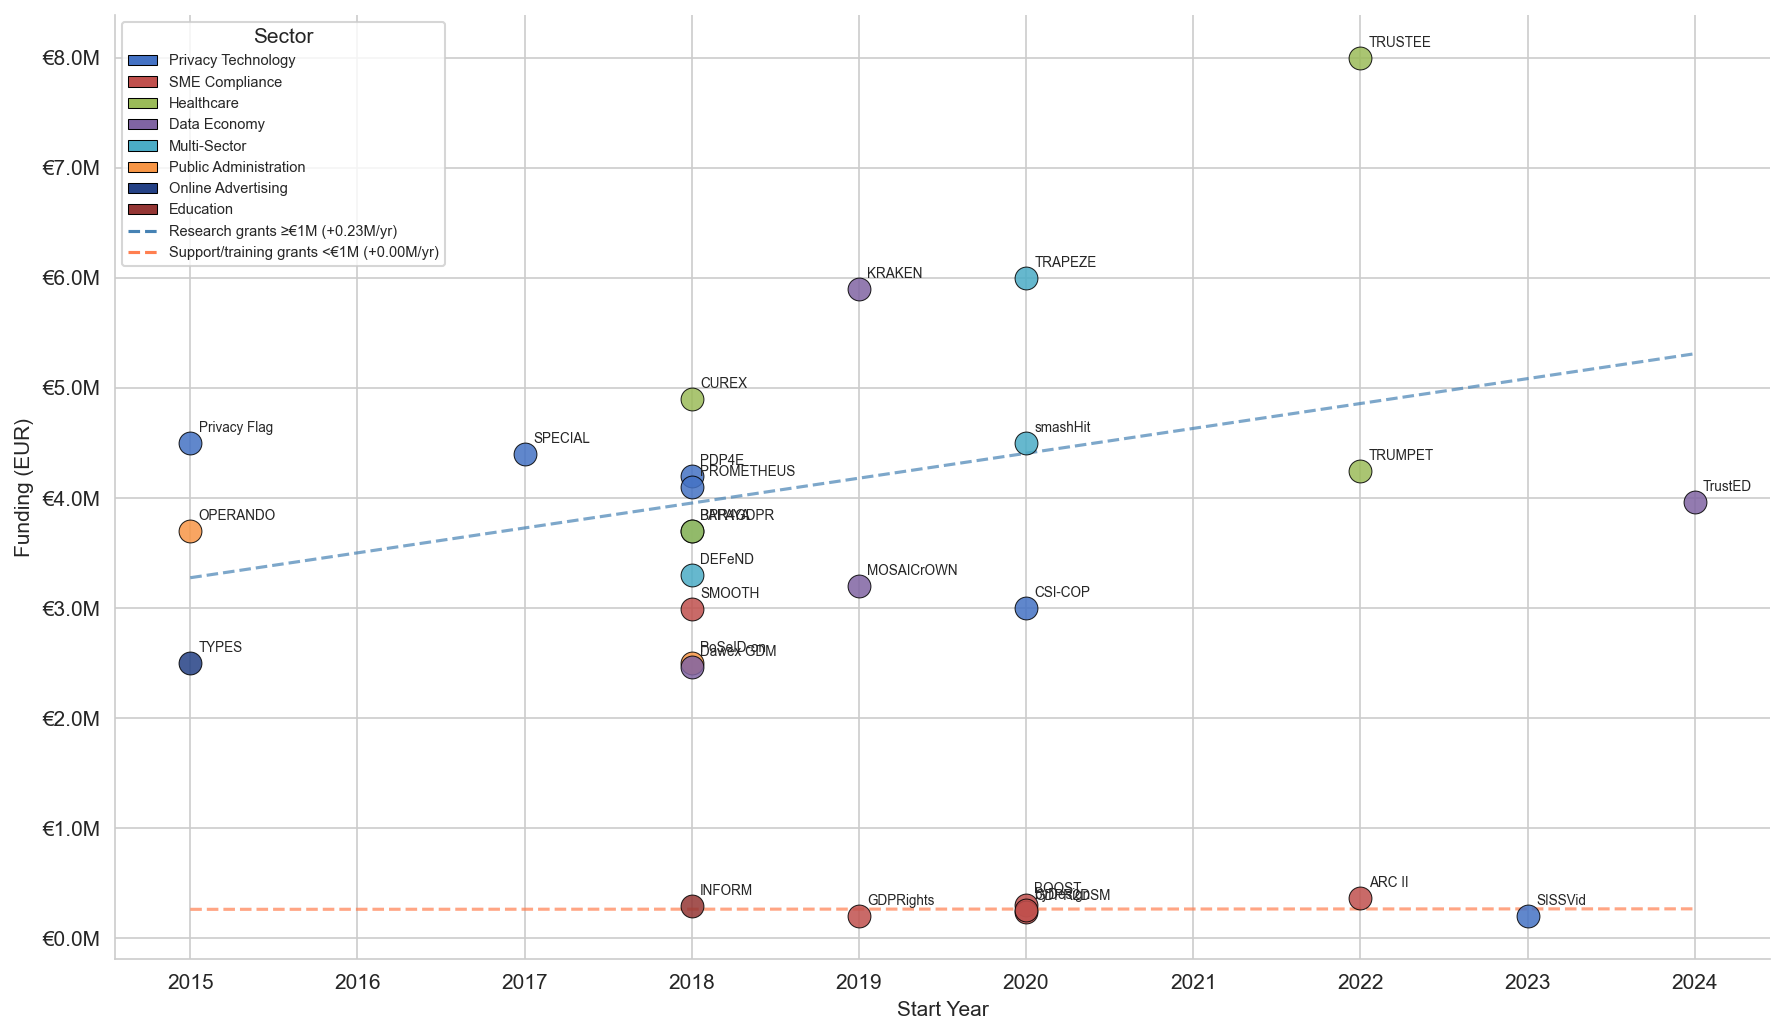

Saved: funding_over_time.png


In [11]:
# Funding over time — scatter colored by sector, split trend lines
fig, ax = plt.subplots(figsize=(12, 7))

for _, row in df_funded.iterrows():
    ax.scatter(
        row['start_year'], row['funding_eur'],
        c=[SECTOR_COLORS.get(row['sector'], 'gray')],
        s=120, edgecolors='black', linewidth=0.5, alpha=0.85, zorder=3
    )
    ax.annotate(row['project_name'],
                (row['start_year'], row['funding_eur']),
                fontsize=6.5, ha='left', va='bottom', xytext=(4, 4),
                textcoords='offset points')

# Split trend lines at €1M threshold
large = df_funded[df_funded['funding_eur'] >= 1_000_000]
small = df_funded[df_funded['funding_eur'] < 1_000_000]

years_range = np.linspace(df_funded['start_year'].min(), df_funded['start_year'].max(), 50)

z_large = None
z_small = None
if len(large) >= 2:
    z_large = np.polyfit(large['start_year'], large['funding_eur'], 1)
    p_large = np.poly1d(z_large)
    ax.plot(years_range, p_large(years_range), '--', color='steelblue', alpha=0.7)

if len(small) >= 2:
    z_small = np.polyfit(small['start_year'], small['funding_eur'], 1)
    p_small = np.poly1d(z_small)
    ax.plot(years_range, p_small(years_range), '--', color='coral', alpha=0.7)

# Legend
handles = [Patch(facecolor=SECTOR_COLORS[s], label=s, edgecolor='black', linewidth=0.5)
           for s in SECTOR_ORDER if s in df_funded['sector'].values]
if z_large is not None:
    handles.append(plt.Line2D([0], [0], linestyle='--', color='steelblue',
                   label=f'Research grants ≥€1M ({z_large[0]/1e6:+.2f}M/yr)'))
if z_small is not None:
    handles.append(plt.Line2D([0], [0], linestyle='--', color='coral',
                   label=f'Support/training grants <€1M ({z_small[0]/1e6:+.2f}M/yr)'))
ax.legend(handles=handles, title='Sector', fontsize=7, loc='upper left')
ax.set_xlabel('Start Year')
ax.set_ylabel('Funding (EUR)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'€{x/1e6:.1f}M'))
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('funding_over_time.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: funding_over_time.png')

## 8. Correlation: Funding vs Consortium Size vs Duration

Pearson r shown in subplot titles. Only projects with both funding and consortium_size (n ≈ 19).

Projects with both funding and consortium size: 19


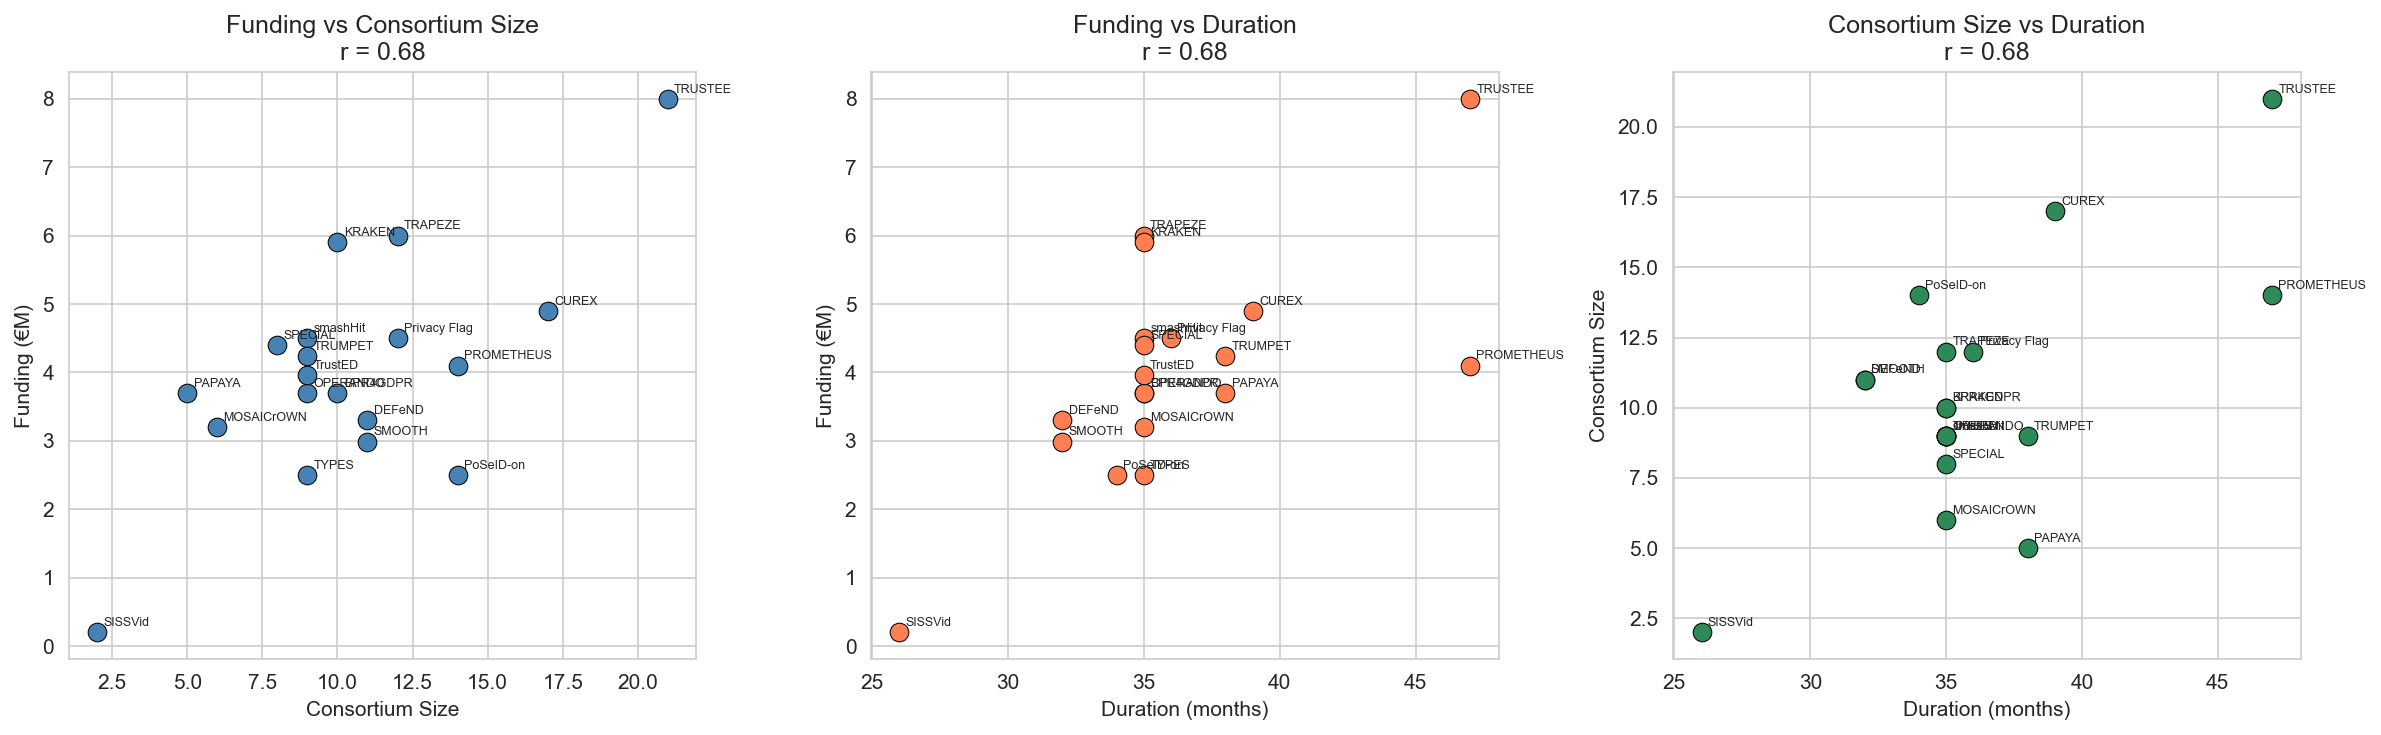

Saved: correlation_plots.png


In [12]:
df_corr = df.dropna(subset=['funding_eur', 'consortium_size'])
print(f'Projects with both funding and consortium size: {len(df_corr)}')

if len(df_corr) >= 5:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    
    axes[0].scatter(df_corr['consortium_size'], df_corr['funding_eur'] / 1e6,
                    c='steelblue', s=80, edgecolors='black', linewidth=0.5)
    for _, r in df_corr.iterrows():
        axes[0].annotate(r['project_name'], (r['consortium_size'], r['funding_eur']/1e6),
                         fontsize=6, xytext=(3, 3), textcoords='offset points')
    corr1 = df_corr['consortium_size'].corr(df_corr['funding_eur'])
    axes[0].set_xlabel('Consortium Size')
    axes[0].set_ylabel('Funding (€M)')
    axes[0].set_title(f'Funding vs Consortium Size\nr = {corr1:.2f}')
    
    axes[1].scatter(df_corr['duration_months'], df_corr['funding_eur'] / 1e6,
                    c='coral', s=80, edgecolors='black', linewidth=0.5)
    for _, r in df_corr.iterrows():
        axes[1].annotate(r['project_name'], (r['duration_months'], r['funding_eur']/1e6),
                         fontsize=6, xytext=(3, 3), textcoords='offset points')
    corr2 = df_corr['duration_months'].corr(df_corr['funding_eur'])
    axes[1].set_xlabel('Duration (months)')
    axes[1].set_ylabel('Funding (€M)')
    axes[1].set_title(f'Funding vs Duration\nr = {corr2:.2f}')
    
    axes[2].scatter(df_corr['duration_months'], df_corr['consortium_size'],
                    c='seagreen', s=80, edgecolors='black', linewidth=0.5)
    for _, r in df_corr.iterrows():
        axes[2].annotate(r['project_name'], (r['duration_months'], r['consortium_size']),
                         fontsize=6, xytext=(3, 3), textcoords='offset points')
    corr3 = df_corr['duration_months'].corr(df_corr['consortium_size'])
    axes[2].set_xlabel('Duration (months)')
    axes[2].set_ylabel('Consortium Size')
    axes[2].set_title(f'Consortium Size vs Duration\nr = {corr3:.2f}')
    
    plt.tight_layout()
    plt.savefig('correlation_plots.png', dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print('Saved: correlation_plots.png')

## 9. Gantt-style Timeline

All 29 projects sorted by start date, colored by sector. Red dashed line = GDPR enforcement (May 25, 2018).

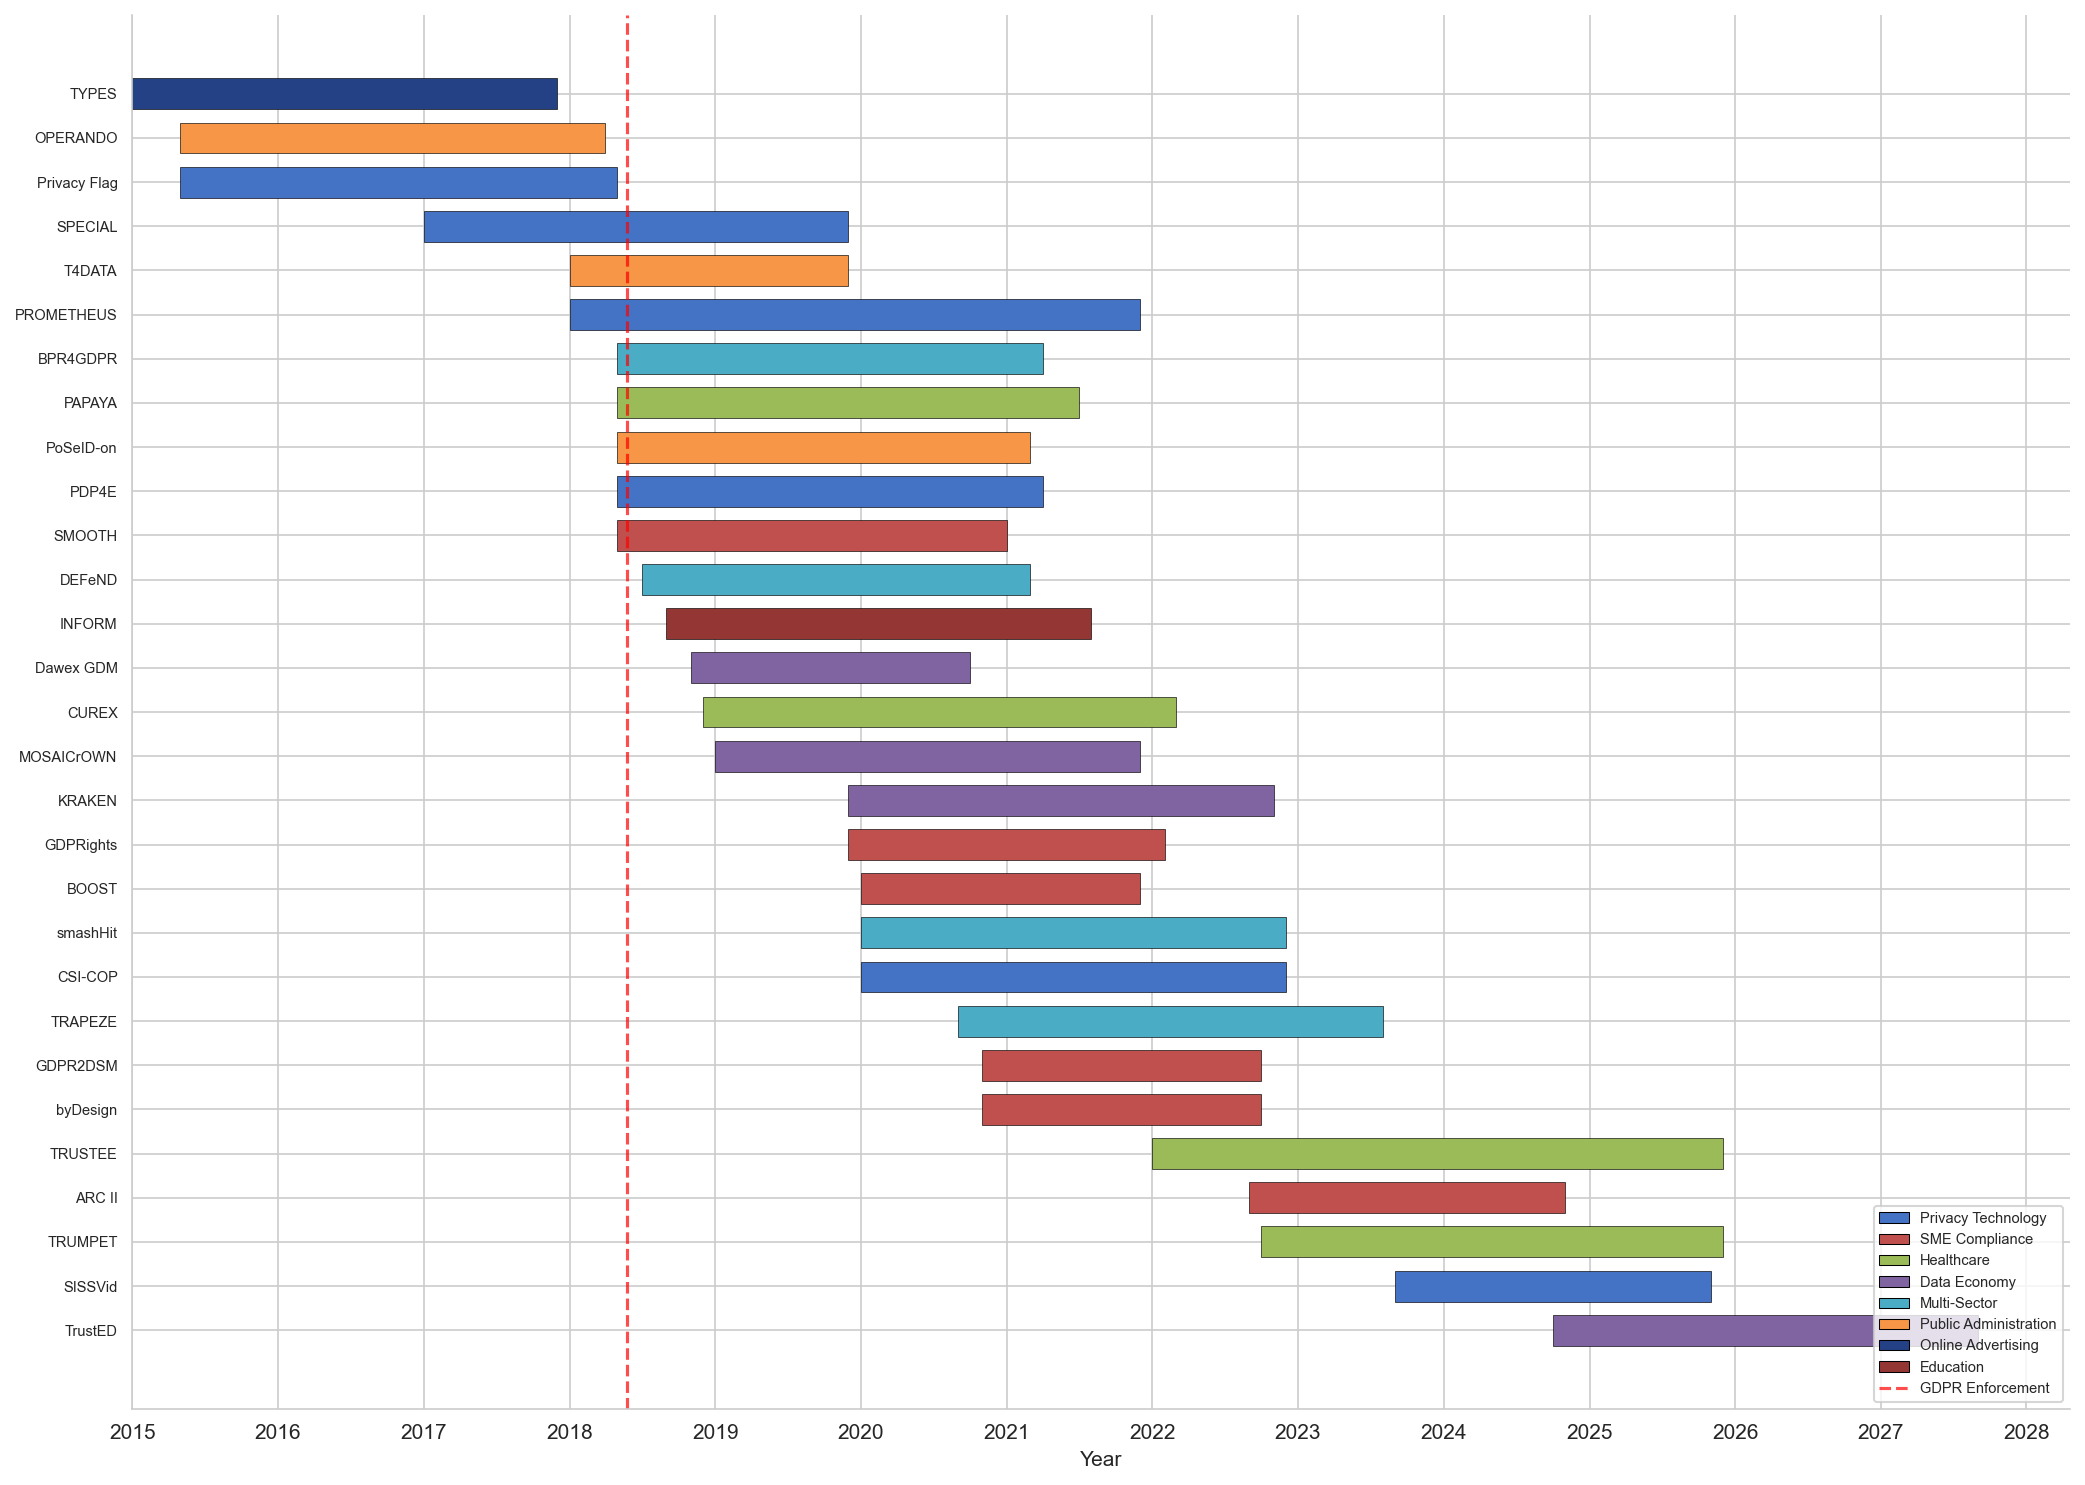

Saved: project_timeline.png


In [13]:
df_sorted = df.sort_values('start_date')

fig, ax = plt.subplots(figsize=(14, 10))
yticks = []
for i, (_, row) in enumerate(df_sorted.iterrows()):
    color = SECTOR_COLORS.get(row['sector'], 'gray')
    start = row['start_date']
    duration = row['end_date'] - row['start_date']
    ax.barh(i, duration, left=start, color=color, edgecolor='black', linewidth=0.3, height=0.7)
    yticks.append(row['project_name'])

ax.set_yticks(range(len(yticks)))
ax.set_yticklabels(yticks, fontsize=7)
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_xlabel('Year')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# GDPR enforcement line
ax.axvline(pd.Timestamp('2018-05-25'), color='red', linestyle='--', alpha=0.7, label='GDPR Enforcement (May 2018)')

handles = [Patch(facecolor=SECTOR_COLORS[s], label=s, edgecolor='black', linewidth=0.5)
           for s in SECTOR_ORDER]
handles.append(plt.Line2D([0], [0], linestyle='--', color='red', alpha=0.7, label='GDPR Enforcement'))
ax.legend(handles=handles, fontsize=7, loc='lower right')
plt.tight_layout()
plt.savefig('project_timeline.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: project_timeline.png')